In [1]:
import pandas as pd
import re
import datetime as dt
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
pd.set_option("display.max_rows", None)

In [3]:
df = pd.read_csv(r"C:\Users\Easy Data\Dropbox (Anterior)\PC\Downloads\movies.csv")

In [4]:
df.shape

(9999, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   MOVIES    9999 non-null   object 
 1   YEAR      9355 non-null   object 
 2   GENRE     9919 non-null   object 
 3   RATING    8179 non-null   float64
 4   ONE-LINE  9999 non-null   object 
 5   STARS     9999 non-null   object 
 6   VOTES     8179 non-null   object 
 7   RunTime   7041 non-null   float64
 8   Gross     460 non-null    object 
dtypes: float64(2), object(7)
memory usage: 703.2+ KB


In [6]:
df.columns=[i.upper() for i in df.columns]

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   MOVIES    9999 non-null   object 
 1   YEAR      9355 non-null   object 
 2   GENRE     9919 non-null   object 
 3   RATING    8179 non-null   float64
 4   ONE-LINE  9999 non-null   object 
 5   STARS     9999 non-null   object 
 6   VOTES     8179 non-null   object 
 7   RUNTIME   7041 non-null   float64
 8   GROSS     460 non-null    object 
dtypes: float64(2), object(7)
memory usage: 703.2+ KB


In [8]:
(df.isnull().sum()/len(df))*100

MOVIES       0.000000
YEAR         6.440644
GENRE        0.800080
RATING      18.201820
ONE-LINE     0.000000
STARS        0.000000
VOTES       18.201820
RUNTIME     29.582958
GROSS       95.399540
dtype: float64

In [9]:
df.head(10)

,MOVIES,YEAR,GENRE,RATING,ONE-LINE,STARS,VOTES,RUNTIME,GROSS
0,Blood Red Sky,(2021),"\nAction, Horror, Thriller",6.1,\nA woman with a mysterious illness is forced ...,\n Director:\nPeter Thorwarth\n| \n Star...,"21,062",121.0,NaN
1,Masters of the Universe: Revelation,(2021– ),"\nAnimation, Action, Adventure",5.0,\nThe war for Eternia begins again in what may...,"\n \n Stars:\nChris Wood, \nSara...","17,870",25.0,NaN
2,The Walking Dead,(2010–2022),"\nDrama, Horror, Thriller",8.2,\nSheriff Deputy Rick Grimes wakes up from a c...,"\n \n Stars:\nAndrew Lincoln, \n...","885,805",44.0,NaN
3,Rick and Morty,(2013– ),"\nAnimation, Adventure, Comedy",9.2,\nAn animated series that follows the exploits...,"\n \n Stars:\nJustin Roiland, \n...","414,849",23.0,NaN
4,Army of Thieves,(2021),"\nAction, Crime, Horror",NaN,"\nA prequel, set before the events of Army of ...",\n Director:\nMatthias Schweighöfer\n| \n ...,NaN,NaN,NaN
5,Outer Banks,(2020– ),"\nAction, Crime, Drama",7.6,\nA group of teenagers from the wrong side of ...,"\n \n Stars:\nChase Stokes, \nMa...","25,858",50.0,NaN
6,The Last Letter from Your Lover,(2021),"\nDrama, Romance",6.8,\nA pair of interwoven stories set in the past...,\n Director:\nAugustine Frizzell\n| \n S...,"5,283",110.0,NaN
7,Dexter,(2006–2013),"\nCrime, Drama, Mystery",8.6,"\nBy day, mild-mannered Dexter is a blood-spat...","\n \n Stars:\nMichael C. Hall, \...","665,387",53.0,NaN
8,Never Have I Ever,(2020– ),\nComedy,7.9,\nThe complicated life of a modern-day first g...,\n \n Stars:\nMaitreyi Ramakrish...,"34,530",30.0,NaN
9,Virgin River,(2019– ),"\nDrama, Romance",7.4,"\nSeeking a fresh start, nurse practitioner Me...",\n \n Stars:\nAlexandra Breckenr...,"27,279",44.0,NaN


In [10]:
num=[i for i in range(1,9,1)]
df["YEAR_DESDE"] = (
    df["YEAR"]
    .astype(str)         
    .str.replace(r"[(,)]", "", regex=True)
    .str.strip()
    .str.split("–")
    .apply(lambda x: x[0] if x[0] in str(num) else " ".join(re.findall(r"\d+",x[0])))
)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MOVIES      9999 non-null   object 
 1   YEAR        9355 non-null   object 
 2   GENRE       9919 non-null   object 
 3   RATING      8179 non-null   float64
 4   ONE-LINE    9999 non-null   object 
 5   STARS       9999 non-null   object 
 6   VOTES       8179 non-null   object 
 7   RUNTIME     7041 non-null   float64
 8   GROSS       460 non-null    object 
 9   YEAR_DESDE  9999 non-null   object 
dtypes: float64(2), object(8)
memory usage: 781.3+ KB


In [12]:
df["YEAR_DESDE"]=pd.to_datetime(df["YEAR_DESDE"],errors="coerce")

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   MOVIES      9999 non-null   object        
 1   YEAR        9355 non-null   object        
 2   GENRE       9919 non-null   object        
 3   RATING      8179 non-null   float64       
 4   ONE-LINE    9999 non-null   object        
 5   STARS       9999 non-null   object        
 6   VOTES       8179 non-null   object        
 7   RUNTIME     7041 non-null   float64       
 8   GROSS       460 non-null    object        
 9   YEAR_DESDE  9251 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(2), object(7)
memory usage: 781.3+ KB


In [14]:
df["YEAR_DESDE"].median()

Timestamp('2018-01-01 00:00:00')

In [15]:
df["YEAR_DESDE"]=df["YEAR_DESDE"].fillna(df["YEAR_DESDE"].median())

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   MOVIES      9999 non-null   object        
 1   YEAR        9355 non-null   object        
 2   GENRE       9919 non-null   object        
 3   RATING      8179 non-null   float64       
 4   ONE-LINE    9999 non-null   object        
 5   STARS       9999 non-null   object        
 6   VOTES       8179 non-null   object        
 7   RUNTIME     7041 non-null   float64       
 8   GROSS       460 non-null    object        
 9   YEAR_DESDE  9999 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(2), object(7)
memory usage: 781.3+ KB


In [17]:
df["YEAR_HASTA"]=df["YEAR"]\
.astype(str)\
.str.replace(r"[(,)]", "", regex=True)\
.str.strip()\
.str.split("–")\
.apply(lambda x: x[1] if len(x)>1  else "" )

In [18]:
df["YEAR_HASTA"]=pd.to_datetime(df["YEAR_HASTA"],errors="coerce")

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   MOVIES      9999 non-null   object        
 1   YEAR        9355 non-null   object        
 2   GENRE       9919 non-null   object        
 3   RATING      8179 non-null   float64       
 4   ONE-LINE    9999 non-null   object        
 5   STARS       9999 non-null   object        
 6   VOTES       8179 non-null   object        
 7   RUNTIME     7041 non-null   float64       
 8   GROSS       460 non-null    object        
 9   YEAR_DESDE  9999 non-null   datetime64[ns]
 10  YEAR_HASTA  1388 non-null   datetime64[ns]
dtypes: datetime64[ns](2), float64(2), object(7)
memory usage: 859.4+ KB


In [20]:
(df["YEAR_HASTA"].isnull().sum()/len(df))*100

np.float64(86.11861186118612)

In [21]:
df=df.drop(["YEAR","YEAR_HASTA"],axis=1)

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   MOVIES      9999 non-null   object        
 1   GENRE       9919 non-null   object        
 2   RATING      8179 non-null   float64       
 3   ONE-LINE    9999 non-null   object        
 4   STARS       9999 non-null   object        
 5   VOTES       8179 non-null   object        
 6   RUNTIME     7041 non-null   float64       
 7   GROSS       460 non-null    object        
 8   YEAR_DESDE  9999 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(2), object(6)
memory usage: 703.2+ KB


In [23]:
#df=df.dropna(subset=["GENRE"])

In [24]:
#df["RATING"]=pd.to_numeric(df["RATING"],errors="coerce")

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   MOVIES      9999 non-null   object        
 1   GENRE       9919 non-null   object        
 2   RATING      8179 non-null   float64       
 3   ONE-LINE    9999 non-null   object        
 4   STARS       9999 non-null   object        
 5   VOTES       8179 non-null   object        
 6   RUNTIME     7041 non-null   float64       
 7   GROSS       460 non-null    object        
 8   YEAR_DESDE  9999 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(2), object(6)
memory usage: 703.2+ KB


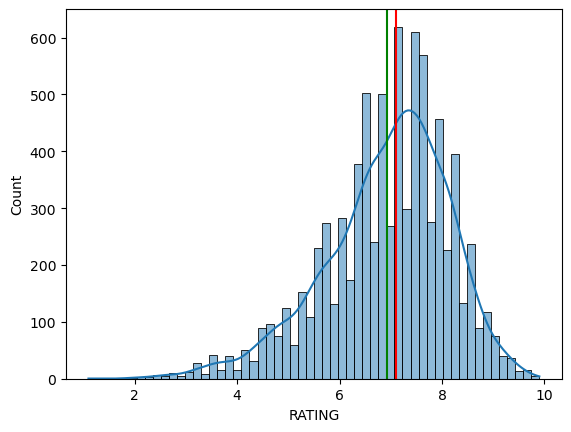

In [26]:
sns.histplot(df["RATING"],kde=True)
plt.axvline(df["RATING"].median(),color="red")
plt.axvline(df["RATING"].mean(),color="green")

In [27]:
df["RATING"]=df["RATING"].fillna(df["RATING"].median())

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9999 entries, 0 to 9998
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   MOVIES      9999 non-null   object        
 1   GENRE       9919 non-null   object        
 2   RATING      9999 non-null   float64       
 3   ONE-LINE    9999 non-null   object        
 4   STARS       9999 non-null   object        
 5   VOTES       8179 non-null   object        
 6   RUNTIME     7041 non-null   float64       
 7   GROSS       460 non-null    object        
 8   YEAR_DESDE  9999 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(2), object(6)
memory usage: 703.2+ KB


In [29]:
(df["GENRE"].isnull().sum()/len(df))*100

np.float64(0.8000800080008)

In [30]:
df.dropna(subset=["GENRE"],axis=0,inplace=True)

In [31]:
df["VOTES"]=pd.to_numeric(df["VOTES"].replace(",",".",regex=True),errors="coerce")

In [32]:
df["VOTES"].isnull().sum()

np.int64(1757)

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9919 entries, 0 to 9998
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   MOVIES      9919 non-null   object        
 1   GENRE       9919 non-null   object        
 2   RATING      9919 non-null   float64       
 3   ONE-LINE    9919 non-null   object        
 4   STARS       9919 non-null   object        
 5   VOTES       8162 non-null   float64       
 6   RUNTIME     7032 non-null   float64       
 7   GROSS       460 non-null    object        
 8   YEAR_DESDE  9919 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), object(5)
memory usage: 774.9+ KB


In [36]:
(df["VOTES"].isnull().sum()/len(df))*100

np.float64(17.71347918136909)

In [37]:
df["VOTES"].describe()

count    8162.000000
mean      171.971678
std       244.958494
min         1.000000
25%         5.171250
50%        49.000000
75%       243.000000
max       999.000000
Name: VOTES, dtype: float64

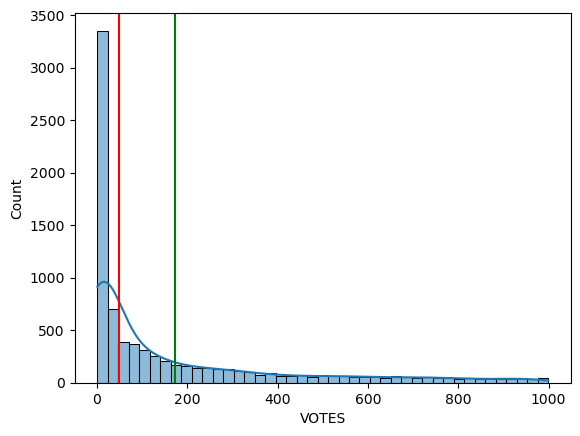

In [38]:
sns.histplot(df["VOTES"],kde=True)
plt.axvline(df["VOTES"].median(),color="red")
plt.axvline(df["VOTES"].mean(),color="green")

In [40]:
df["VOTES"]=df["VOTES"].fillna(df["VOTES"].median())
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9919 entries, 0 to 9998
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   MOVIES      9919 non-null   object        
 1   GENRE       9919 non-null   object        
 2   RATING      9919 non-null   float64       
 3   ONE-LINE    9919 non-null   object        
 4   STARS       9919 non-null   object        
 5   VOTES       9919 non-null   float64       
 6   RUNTIME     7032 non-null   float64       
 7   GROSS       460 non-null    object        
 8   YEAR_DESDE  9919 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), object(5)
memory usage: 774.9+ KB


In [44]:
df["RUNTIME"]=df["RUNTIME"].fillna(df["RUNTIME"].median())

In [47]:
df.drop(["GROSS"],axis=1,inplace=True)

In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9919 entries, 0 to 9998
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   MOVIES      9919 non-null   object        
 1   GENRE       9919 non-null   object        
 2   RATING      9919 non-null   float64       
 3   ONE-LINE    9919 non-null   object        
 4   STARS       9919 non-null   object        
 5   VOTES       9919 non-null   float64       
 6   RUNTIME     9919 non-null   float64       
 7   YEAR_DESDE  9919 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), object(4)
memory usage: 955.5+ KB


In [58]:
df["MOVIES"]=df["MOVIES"].astype(str).apply(lambda x: x.lower())

In [65]:
for i in df.select_dtypes(include=["object"]):
    print(i)
    df["MOVIES"]=df["MOVIES"].astype(str).apply(lambda x: x.lower())
    df[i]=df[i].astype(str).apply(lambda x: x.lower())
    

MOVIES
GENRE
ONE-LINE
STARS


In [63]:
df

,MOVIES,GENRE,RATING,ONE-LINE,STARS,VOTES,RUNTIME,YEAR_DESDE
0,blood red sky,"\naction, horror, thriller",6.1,\na woman with a mysterious illness is forced ...,\n director:\npeter thorwarth\n| \n star...,21.062,121.0,2021-01-01
1,masters of the universe: revelation,"\nanimation, action, adventure",5.0,\nthe war for eternia begins again in what may...,"\n \n stars:\nchris wood, \nsara...",17.870,25.0,2021-01-01
2,the walking dead,"\ndrama, horror, thriller",8.2,\nsheriff deputy rick grimes wakes up from a c...,"\n \n stars:\nandrew lincoln, \n...",885.805,44.0,2010-01-01
3,rick and morty,"\nanimation, adventure, comedy",9.2,\nan animated series that follows the exploits...,"\n \n stars:\njustin roiland, \n...",414.849,23.0,2013-01-01
4,army of thieves,"\naction, crime, horror",7.1,"\na prequel, set before the events of army of ...",\n director:\nmatthias schweighöfer\n| \n ...,49.000,60.0,2021-01-01
5,outer banks,"\naction, crime, drama",7.6,\na group of teenagers from the wrong side of ...,"\n \n stars:\nchase stokes, \nma...",25.858,50.0,2020-01-01
6,the last letter from your lover,"\ndrama, romance",6.8,\na pair of interwoven stories set in the past...,\n director:\naugustine frizzell\n| \n s...,5.283,110.0,2021-01-01
7,dexter,"\ncrime, drama, mystery",8.6,"\nby day, mild-mannered dexter is a blood-spat...","\n \n stars:\nmichael c. hall, \...",665.387,53.0,2006-01-01
8,never have i ever,\ncomedy,7.9,\nthe complicated life of a modern-day first g...,\n \n stars:\nmaitreyi ramakrish...,34.530,30.0,2020-01-01
9,virgin river,"\ndrama, romance",7.4,"\nseeking a fresh start, nurse practitioner me...",\n \n stars:\nalexandra breckenr...,27.279,44.0,2019-01-01


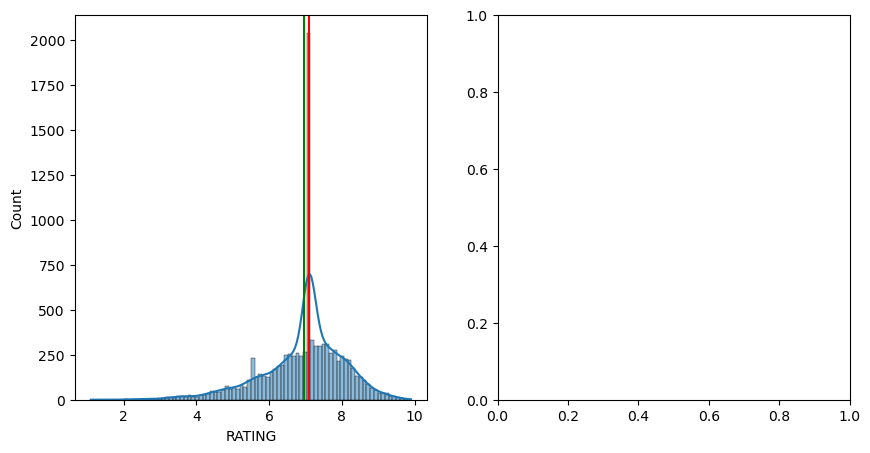

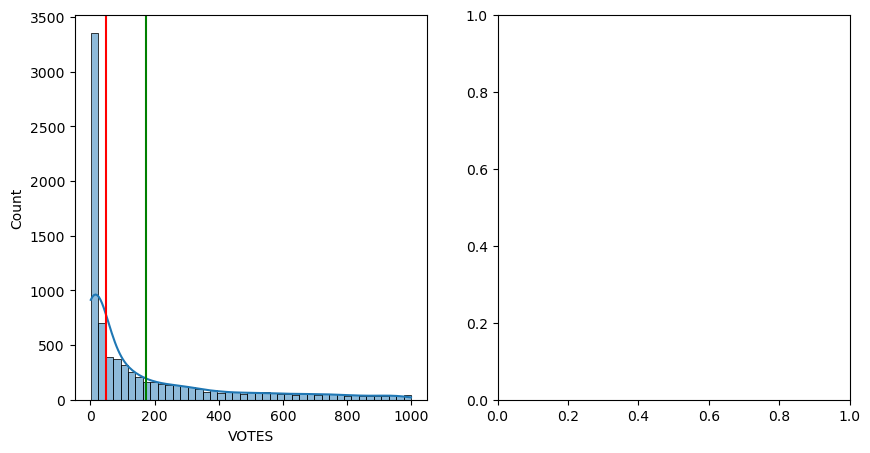

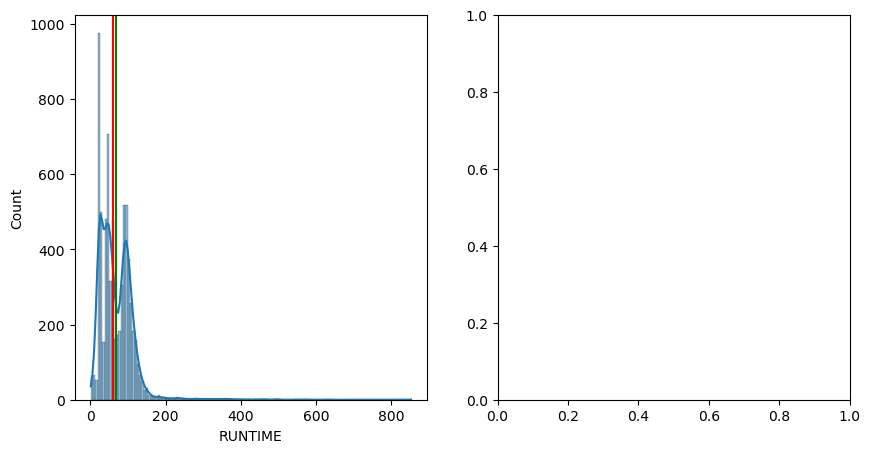

In [34]:
for i in df.select_dtypes(include=["float64"]):
    fig,ax=plt.subplots(1,2,figsize=(10,5))
    sns.histplot(df[i],kde=True,ax=ax[0])
    ax[0].axvline(df[i].median(),color="red")
    ax[0].axvline(df[i].mean(),color="green")

    
    